# Mask models compared: Kirchhoff, film, boundary layer and RCWA

Notebook 36 introduced the rigorous mask (`RigorousMask`, RCWA) and showed
that rigorous lines print wider than the film model predicts. This notebook
puts the mask models side by side, order by order, and asks where the
cheaper ones stop being good enough.

The four models, from the simplest to the rigorous one:

| model | stack | what it knows |
|---|---|---|
| **Kirchhoff** | `ThinMask.binary()`, `ThinMask.att_psm(0.06, 180)` | nominal transmission and phase of the absorber, infinitely thin |
| **film** | `RigorousMask.film_mask()` | true transmission of the absorber film for each angle and polarization, but no edges |
| **boundary layer** | film + `BoundaryLayer` from `calibrate_boundary_layer()` | edge strips with two complex transmissions, fitted to RCWA |
| **RCWA** | `RigorousMask` | Maxwell's equations for the patterned absorber, per source point |

The masks are the same as in notebooks 32 and 36: a 68 nm MoSi attenuated
PSM (6 %) and a 70 nm chrome binary mask, ArF immersion (193 nm, water,
NA 1.35, 4×), lines and spaces with lines along y.

Contents:

1. Convergence of the RCWA over the number of harmonics.
2. The diffraction orders one by one, at one pitch.
3. Order amplitudes and phases through pitch.
4. Where the thin models break down: order errors over pitch and duty
   cycle.
5. Imaging: CD, best focus and NILS through pitch.
6. Imaging errors over pitch and duty cycle.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from pyoptics.litho import (Illumination, LithoSimulation, MaskLayout, Projector, RigorousMask, ThinMask,
                            lens, rcwa)

plt.rcParams.update({"figure.dpi": 100, "font.size": 11})

wl, n_w, NA, M = 193.0, 1.437, 1.35, 4.0
MOSI, CR, BLANK = 2.343 + 0.586j, 0.84 + 1.65j, 1.563  # as in notebooks 32 and 36
mosi = RigorousMask([(MOSI, 68.0)], name="MoSi 68 nm (6 % att. PSM)")
chrome = RigorousMask([(CR, 70.0)], name="Cr 70 nm (binary)")
masks = (mosi, chrome)
kirchhoff = {mosi.name: ThinMask.att_psm(0.06, 180.0), chrome.name: ThinMask.binary()}
projector = Projector(NA, wl, n=n_w)
zero = np.zeros(1)

for rig in masks:
    t_film = rig.film_mask().jones(zero, zero, NA, wl, M)[1][0][0, 0]
    t_k = kirchhoff[rig.name].t_absorber
    print(f"{rig.name}: absorber transmission Kirchhoff {abs(t_k)**2:.4f} at {np.degrees(np.angle(t_k)):.0f}°, "
          f"film {abs(t_film)**2:.4f} at {np.degrees(np.angle(t_film)):.0f}°")

MoSi 68 nm (6 % att. PSM): absorber transmission Kirchhoff 0.0600 at 180°, film 0.0638 at 165°
Cr 70 nm (binary): absorber transmission Kirchhoff 0.0000 at 0°, film 0.0009 at -34°


The film transmission is what a laterally infinite absorber transmits,
relative to the bare blank. For MoSi it is close to the nominal 6 % but
its phase is 165° instead of 180° (68 nm is a bit thin for 180°). Chrome
leaks 0.1 % of the intensity; Kirchhoff assumes zero.

Two helpers give the orders at normal incidence as complex amplitudes
(TM: $E_x$ across the lines, TE: $E_y$ along them). For the thin models
they are the Fourier coefficients of the regions times their
transmissions, which is what `LithoSimulation` uses internally; for RCWA
they come from `RigorousMask.order_jones()`.

In [2]:
def thin_orders(stack, layout, m):
    """Orders m (along x) of a thin model at normal incidence, shape (2, len(m)): TM, TE."""
    J_clear, J_abs = (np.asarray(J)[0] for J in stack.jones(zero, zero, NA, wl, M))
    bl = stack.boundary_layer
    c = layout.region_coefficients(m, [0], 0.0 if bl is None else bl.width)
    J = {"field": J_clear, "feature": J_abs} if layout.tone == "clear" else {"field": J_abs, "feature": J_clear}
    if bl is not None:
        J["edge_y"] = bl.jones()[0]
    return np.array([sum(c[r][0]*J[r][k, k] for r in J) for k in (0, 1)])


def rigorous_orders(rig, layout, m):
    """Orders m of a RigorousMask at normal incidence, shape (2, len(m)): TM, TE."""
    J = rig.order_jones(layout, m, [0], zero, zero, NA, wl, M)[0][:, :, 0]
    return np.array([J[0, 0], J[1, 1]])


def pitch_axis(ax, ticks=(100, 200, 400, 800)):
    """Log pitch axis with plain tick labels."""
    ax.set_xscale("log")
    ax.set_xticks([t for t in ticks if t <= ax.get_xlim()[1]*1.01])
    ax.xaxis.set_major_formatter(plt.ScalarFormatter())
    ax.xaxis.set_minor_formatter(plt.NullFormatter())


def pupil_orders(pitch):
    """Orders that can reach the pupil for some source point (|m| lambda/p <= 2 NA)."""
    n = int(np.floor(2*NA*pitch/wl))
    return np.arange(-n, n + 1)

## 1. Convergence over the number of harmonics

RCWA expands the fields and the permittivity in harmonics $m =
-N..N$ (`n_orders=N`). The more harmonics, the better the sharp absorber
edges are resolved, at a cost that grows like $N^3$. Below: the largest
error of the orders that reach the pupil against a reference with
$N = 128$, for 1:1 lines at 130 nm and 400 nm pitch (wafer scale; 520 nm
and 1600 nm on the mask), TE and TM. The dotted lines mark the default
of `RigorousMask`, about twice as many harmonics as propagate in the
blank.

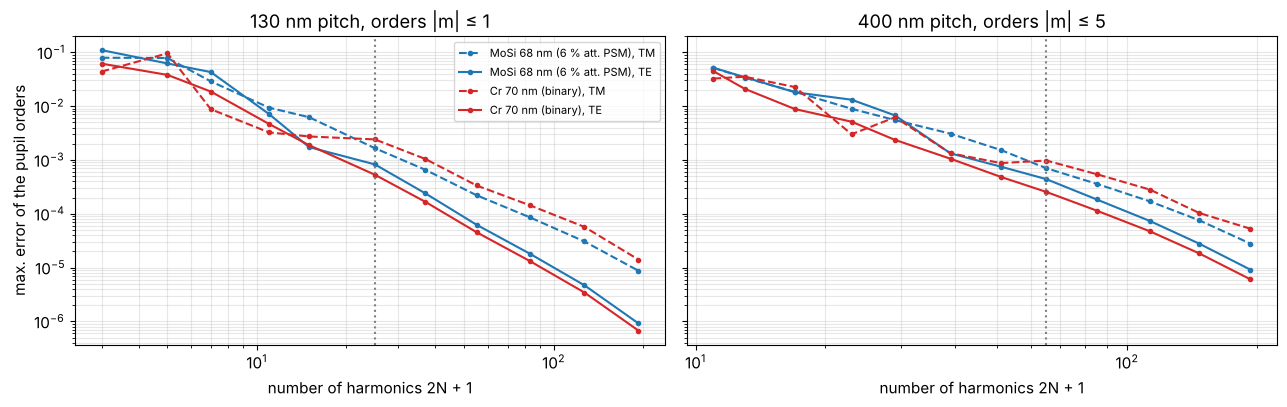

In [3]:
def with_orders(rig, n):
    return RigorousMask([(a, t) for a, _, t in rig.layers], n_orders=n, name=rig.name)


def default_orders(pitch):
    return max(10, 2*int(np.ceil(M*pitch*(BLANK + NA/M)/wl)))


fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, pitch in zip(axes, (130.0, 400.0)):
    layout = MaskLayout.lines_spaces(pitch, pitch/2)
    m = pupil_orders(pitch)
    ns = np.unique(np.geomspace(m.max(), 96, 12).astype(int))
    for rig, c in zip(masks, ("C0", "C3")):
        ref = rigorous_orders(with_orders(rig, 128), layout, m)
        err = np.array([np.abs(rigorous_orders(with_orders(rig, n), layout, m) - ref).max(axis=1) for n in ns])
        ax.loglog(2*ns + 1, err[:, 0], "--", marker="o", ms=3, color=c, label=f"{rig.name}, TM")
        ax.loglog(2*ns + 1, err[:, 1], "-", marker="o", ms=3, color=c, label=f"{rig.name}, TE")
    ax.axvline(2*default_orders(pitch) + 1, color="gray", ls=":")
    ax.set_xlabel("number of harmonics 2N + 1")
    ax.set_title(f"{pitch:.0f} nm pitch, orders |m| ≤ {m.max()}")
    ax.grid(alpha=0.3, which="both")
axes[0].set_ylabel("max. error of the pupil orders")
axes[0].legend(fontsize=8)
plt.tight_layout()

The errors fall roughly like $N^{-2}$ for both polarizations (Li's
factorization, see notebook 36). The default gives errors of a few
$10^{-3}$ of the clear-field amplitude. What matters in the end is the
image: CD, best focus and NILS of the 130 nm pitch through the number of
harmonics, with the run time of one `feature_response()` (64 source
points, 9 foci).

MoSi 68 nm (6 % att. PSM): CD 74.92 nm, best focus -1.20 nm, NILS 1.747 (N = 48); default N = 12: ΔCD = -0.31 nm
Cr 70 nm (binary): CD 52.47 nm, best focus -5.85 nm, NILS 1.499 (N = 48); default N = 12: ΔCD = -0.03 nm


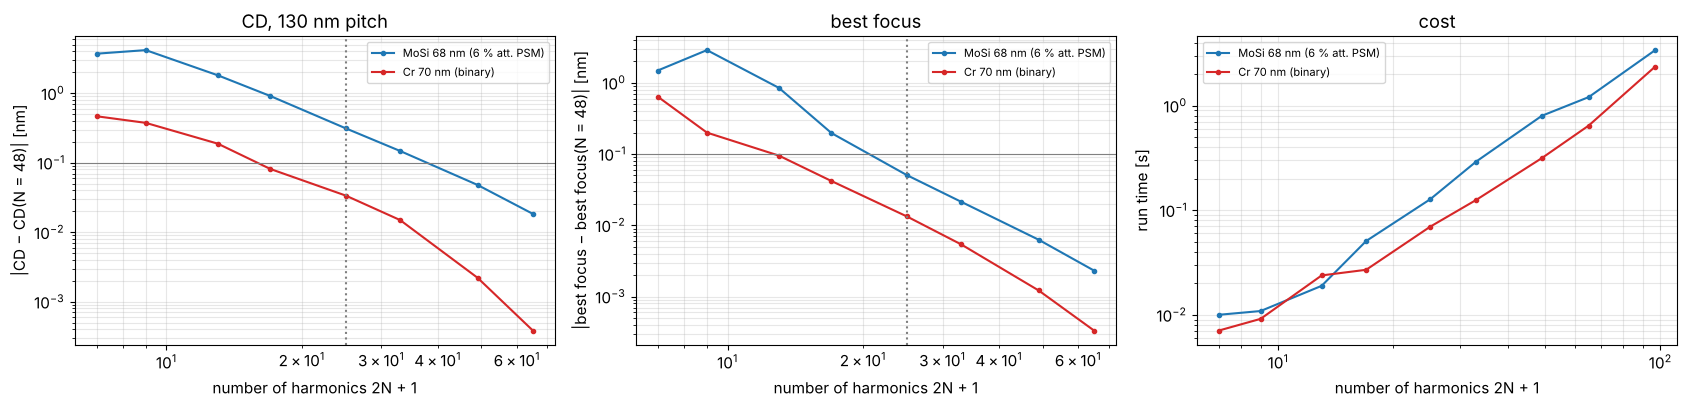

In [4]:
ill = Illumination.annular(0.9, 0.6, n_samples=15, polarization="TE")
foci = np.linspace(-80, 80, 9)
i_f0 = int(np.argmin(np.abs(foci)))
layout = MaskLayout.lines_spaces(130.0, 65.0)
ns = np.array([3, 4, 6, 8, 12, 16, 24, 32, 48])
conv = {}
for rig in masks:
    rows = []
    for n in ns:
        t0 = time.perf_counter()
        r = lens.feature_response(LithoSimulation(layout, with_orders(rig, n), ill, projector),
                                  threshold=0.25, foci=foci)
        rows.append((r.cd, r.best_focus, r.nils_focus[i_f0], time.perf_counter() - t0))
    conv[rig.name] = np.array(rows)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for rig, c in zip(masks, ("C0", "C3")):
    v = conv[rig.name]
    axes[0].loglog(2*ns[:-1] + 1, np.abs(v[:-1, 0] - v[-1, 0]), marker="o", ms=3, color=c, label=rig.name)
    axes[1].loglog(2*ns[:-1] + 1, np.abs(v[:-1, 1] - v[-1, 1]), marker="o", ms=3, color=c, label=rig.name)
    axes[2].loglog(2*ns + 1, v[:, 3], marker="o", ms=3, color=c, label=rig.name)
    print(f"{rig.name}: CD {v[-1, 0]:.2f} nm, best focus {v[-1, 1]:.2f} nm, NILS {v[-1, 2]:.3f} (N = {ns[-1]}); "
          f"default N = {default_orders(130.0)}: ΔCD = {np.interp(default_orders(130.0), ns, v[:, 0]) - v[-1, 0]:+.2f} nm")
for ax in axes[:2]:
    ax.axvline(2*default_orders(130.0) + 1, color="gray", ls=":")
    ax.axhline(0.1, color="gray", lw=0.8)
axes[0].set_ylabel("|CD − CD(N = 48)| [nm]"); axes[1].set_ylabel("|best focus − best focus(N = 48)| [nm]")
axes[2].set_ylabel("run time [s]")
axes[0].set_title("CD, 130 nm pitch"); axes[1].set_title("best focus"); axes[2].set_title("cost")
for ax in axes:
    ax.set_xlabel("number of harmonics 2N + 1"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
plt.tight_layout()

Chrome converges quickly: at the default ($N = 12$, 25 harmonics) CD and
best focus are within 0.03 nm of the converged values. MoSi, a weaker
absorber with a high refractive index ($n = 2.34$), needs more harmonics:
0.3 nm of CD at the default, 0.05 nm at $N = 24$. The cost of the image
grows from about 0.1 s at the default to 1 s at $N = 32$. The default is
good enough for this notebook, because the differences between the models
below are 10 to 100 times larger. For CD work at the 0.1 nm level on MoSi,
double `n_orders`.

## 2. The orders one by one

The boundary layers are calibrated as in notebook 36, here on duty cycles
0.35, 0.5 and 0.65 at five pitches. Then the orders of 1:1 lines at 260 nm
pitch, where orders up to $\pm 3$ reach the pupil: amplitudes (top) and
phases (bottom) at normal incidence, TE filled and TM open markers. The
table gives the ratio to the RCWA order and the phase error.

MoSi 68 nm (6 % att. PSM): w = 8.0 nm, t_TE = -0.296-0.049j, t_TM = 0.201+0.525j
Cr 70 nm (binary): w = 9.0 nm, t_TE = 0.281-0.499j, t_TM = 0.244+0.243j
amplitude ratio |a_model/a_RCWA| and phase error [°] of orders 0..3 (TE / TM):
  MoSi Kirchhoff       0: 1.11   -4° / 1.02  -10° | 1: 0.99   +4° / 1.01   +3° | 2: 0.00 +173° / 0.00 -107° | 3: 0.96  +14° / 1.13   +5°
  MoSi film            0: 1.12   +1° / 1.02   -5° | 1: 1.00   +1° / 1.01   +0° | 2: 0.00 +170° / 0.00 -110° | 3: 0.96  +12° / 1.13   +2°
  MoSi boundary layer  0: 1.00   +0° / 1.00   +0° | 1: 0.99   +1° / 1.01   +0° | 2: 0.95   +0° / 1.00   +3° | 3: 0.92  +12° / 1.09   +2°
  Cr 7 Kirchhoff       0: 1.00   +5° / 1.01   -1° | 1: 1.01   +0° / 1.05   -1° | 2: 0.00 +116° / 0.00 -132° | 3: 0.92  +13° / 1.33   -4°
  Cr 7 film            0: 1.02   +4° / 1.04   -2° | 1: 0.99   +1° / 1.02   -0° | 2: 0.00 +117° / 0.00 -131° | 3: 0.90  +15° / 1.29   -3°
  Cr 7 boundary layer  0: 0.99   +0° / 1.00   -0° | 1: 0.98   +1° / 1.02   -0° | 2:

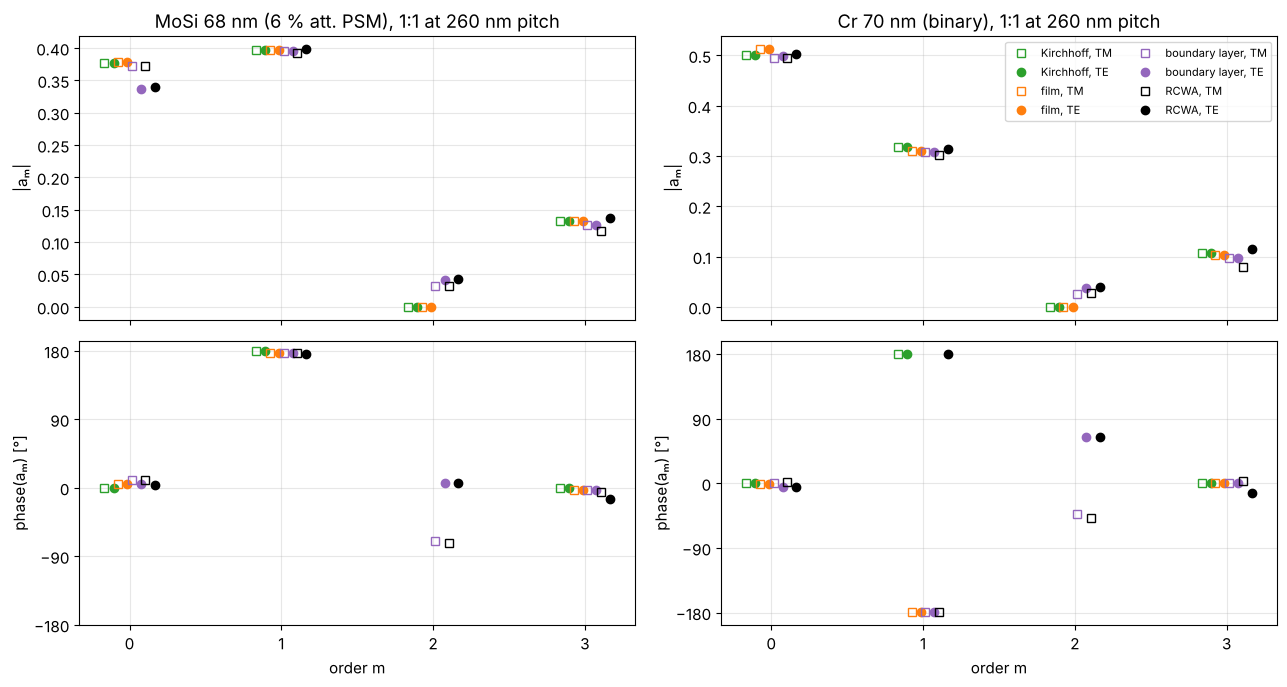

In [5]:
cal_layouts = [MaskLayout.lines_spaces(p, d*p) for p in (100, 130, 180, 260, 400) for d in (0.35, 0.5, 0.65)]
cals = {rig.name: rcwa.calibrate_boundary_layer(rig, cal_layouts, NA, wl, M) for rig in masks}
for rig in masks:
    bl = cals[rig.name].boundary_layer
    print(f"{rig.name}: w = {bl.width:.1f} nm, t_TE = {bl.t_TE:.3f}, t_TM = {bl.t_TM:.3f}")


def models(rig):
    """The four models of a rigorous mask, from the simplest to RCWA."""
    return {"Kirchhoff": kirchhoff[rig.name], "film": rig.film_mask(),
            "boundary layer": cals[rig.name].stack, "RCWA": rig}


def orders(stack, layout, m):
    return rigorous_orders(stack, layout, m) if rcwa.is_rigorous(stack) else thin_orders(stack, layout, m)


colors = {"Kirchhoff": "C2", "film": "C1", "boundary layer": "C4", "RCWA": "k"}
layout = MaskLayout.lines_spaces(260.0, 130.0)
m = np.arange(0, 4)
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for col, rig in enumerate(masks):
    for j, (name, stack) in enumerate(models(rig).items()):
        a = orders(stack, layout, m)
        for k, (pol, marker) in enumerate((("TM", "s"), ("TE", "o"))):
            x = m + 0.09*(j - 1.5) + 0.03*(2*k - 1)
            kw = dict(marker=marker, ls="none", ms=6, color=colors[name], mfc="none" if k == 0 else colors[name])
            axes[0, col].plot(x, np.abs(a[k]), label=f"{name}, {pol}", **kw)
            phase = np.where(np.abs(a[k]) > 1e-6, np.degrees(np.angle(a[k])), np.nan)  # undefined for zero orders
            axes[1, col].plot(x, phase, **kw)
    axes[0, col].set_title(f"{rig.name}, 1:1 at 260 nm pitch")
    axes[0, col].set_ylabel("|aₘ|"); axes[1, col].set_ylabel("phase(aₘ) [°]")
    axes[1, col].set_xlabel("order m"); axes[1, col].set_xticks(m)
    axes[1, col].set_yticks(np.arange(-180, 181, 90))
for ax in axes.flat:
    ax.grid(alpha=0.3)
axes[0, 1].legend(fontsize=8, ncol=2)
plt.tight_layout()

print("amplitude ratio |a_model/a_RCWA| and phase error [°] of orders 0..3 (TE / TM):")
for rig in masks:
    a_ref = orders(rig, layout, m)
    for name, stack in list(models(rig).items())[:3]:
        a = orders(stack, layout, m)
        cells = []
        for mi in m:
            r = a[:, mi]/a_ref[:, mi]
            cells.append(f"{mi}: " + " / ".join(f"{abs(x):.2f} {np.degrees(np.angle(x)):+4.0f}°" for x in r[::-1]))
        print(f"  {rig.name[:4]} {name:15s} " + " | ".join(cells))

What the table and the plots show:

- **Zeroth order.** Kirchhoff and film make the MoSi zeroth order 11 % too
  strong in TE. The thick absorber shadows more of the clear area for E
  along the lines. The Kirchhoff orders are also off in phase by 4° to 10°,
  mostly because the nominal 180° is really 165°.
- **First order.** All thin models are within a few percent and a few
  degrees at this pitch.
- **Second order.** For 1:1 lines the thin models have no even orders: the
  Fourier coefficient of a 50 % duty cycle vanishes. RCWA has $|a_2|
  \approx 0.03$–$0.04$, about 10 % of the first order, because the thick
  edges make the effective line wider than the space. Only the boundary
  layer reproduces it: its edge strips shift the effective duty cycle.
- **Third order.** All thin models are off by 4 % to 33 % and up to 15°. The
  boundary layer is fitted mainly to the low orders and does not fix this.
  The third order reaches the pupil only for some source points, so it
  matters less for the image.

## 3. Order amplitudes and phases through pitch

For 1:1 lines from 80 to 800 nm pitch: the amplitudes of the zeroth and
first orders relative to RCWA, and the error of the phase difference
between the first and the zeroth order. That phase difference acts like a
pupil phase between the orders, i.e. like defocus for that pitch.

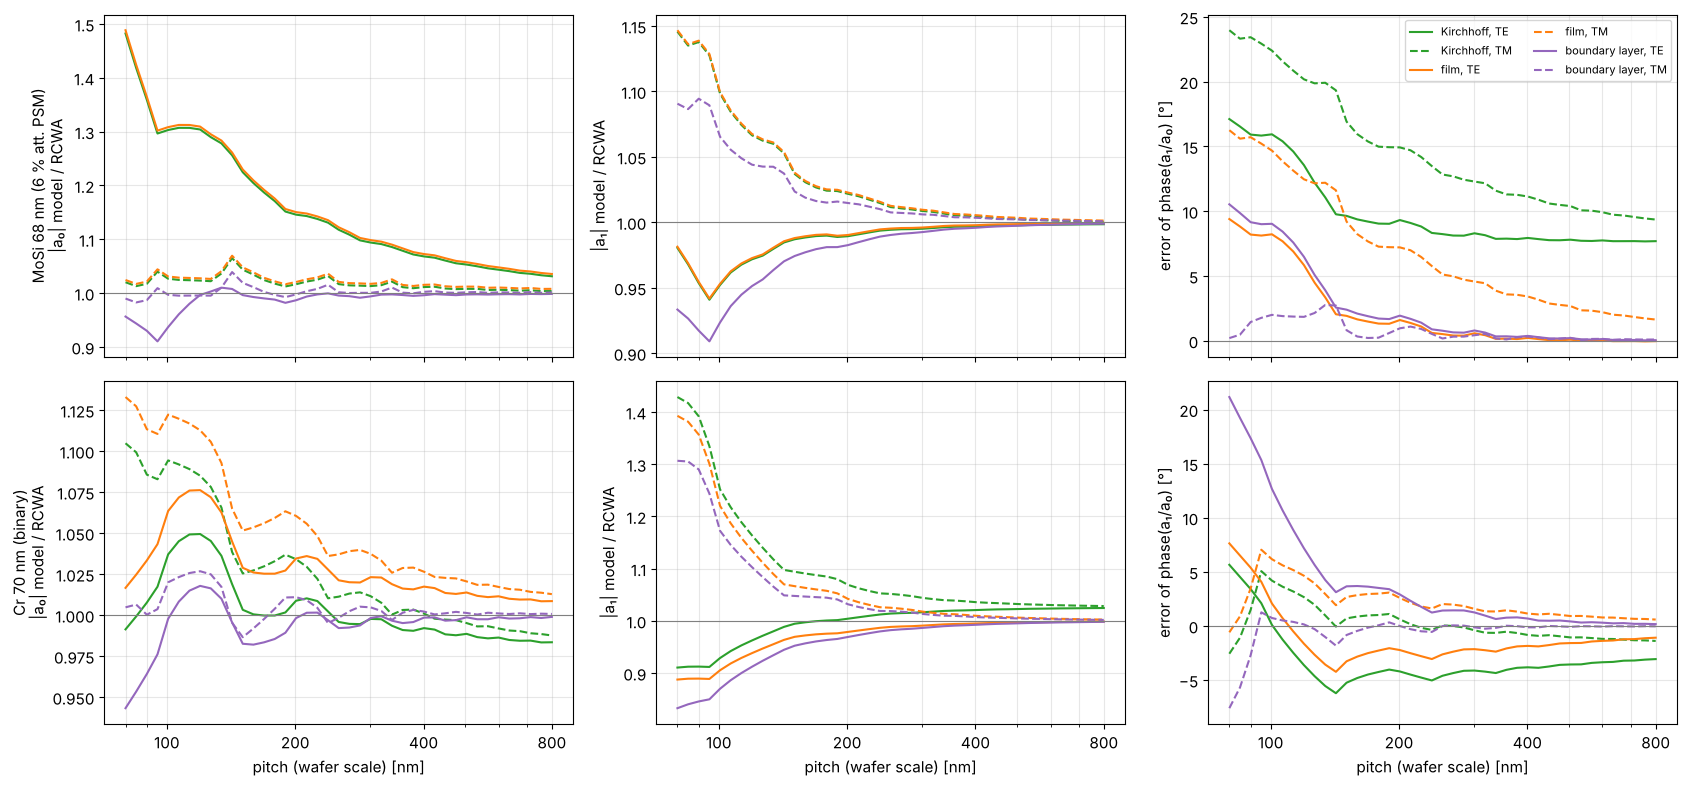

In [6]:
pitches = np.geomspace(80, 800, 41)
m = np.arange(-1, 2)
amps = {}
for rig in masks:
    for name, stack in models(rig).items():
        amps[rig.name, name] = np.array([orders(stack, MaskLayout.lines_spaces(p, p/2), m) for p in pitches])

fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharex=True)
for row, rig in zip(axes, masks):
    ref = amps[rig.name, "RCWA"]
    for name in ("Kirchhoff", "film", "boundary layer"):
        a = amps[rig.name, name]
        for k, ls in ((1, "-"), (0, "--")):
            lab = f"{name}, {'TE' if k else 'TM'}"
            row[0].plot(pitches, np.abs(a[:, k, 1])/np.abs(ref[:, k, 1]), ls, color=colors[name], label=lab)
            row[1].plot(pitches, np.abs(a[:, k, 2])/np.abs(ref[:, k, 2]), ls, color=colors[name], label=lab)
            dphi = np.angle(a[:, k, 2]/a[:, k, 1]) - np.angle(ref[:, k, 2]/ref[:, k, 1])
            row[2].plot(pitches, np.degrees(np.angle(np.exp(1j*dphi))), ls, color=colors[name], label=lab)
    row[0].set_ylabel(f"{rig.name}\n|a₀| model / RCWA")
    row[1].set_ylabel("|a₁| model / RCWA"); row[2].set_ylabel("error of phase(a₁/a₀) [°]")
    row[0].axhline(1, color="gray", lw=0.8); row[1].axhline(1, color="gray", lw=0.8)
    row[2].axhline(0, color="gray", lw=0.8)
for ax in axes.flat:
    pitch_axis(ax); ax.grid(alpha=0.3, which="both")
for ax in axes[1]:
    ax.set_xlabel("pitch (wafer scale) [nm]")
axes[0, 2].legend(fontsize=8, ncol=2)
plt.tight_layout()

- The errors fall off roughly like 1/pitch. They come from the edges, and
  the edges make up a smaller part of a larger period.
- **MoSi:** the TE zeroth order of Kirchhoff and film is 30 % to 50 % too
  strong below 120 nm pitch and still 4 % too strong at 800 nm. Kirchhoff
  keeps a phase error of 8° (TE) to 10° (TM) between the orders even at
  800 nm. That is the nominal 180° against the real 165°, a material error
  and not a 3D effect. The film model removes it at large pitches, but
  below 150 nm both models are 10° to 24° off. The boundary layer keeps the
  zeroth order within a few percent and the phase within 2° to 3° above
  about 120 nm.
- **Chrome:** the first order is too strong in TM (by 40 % at 80 nm and
  10 % at 150 nm) and too weak in TE. The phase errors of the thin models
  stay below 6°. The boundary layer is worse than the film model at the
  smallest pitches (20° phase error in TE at 80 nm). It was calibrated from
  100 nm pitch up and cannot follow the coupling between edges that close
  together.

## 4. Where the thin models break down

One number per layout: the relative rms error of all orders that reach the
pupil, TE and TM together,

$$\varepsilon = \sqrt{\frac{\sum_{m,\,\mathrm{pol}} |a_m^\mathrm{model} -
a_m^\mathrm{RCWA}|^2}{\sum_{m,\,\mathrm{pol}} |a_m^\mathrm{RCWA}|^2}},$$

(the quantity that `calibrate_boundary_layer()` minimizes), over pitch and
duty cycle (line width / pitch). Contours at 5 % and 10 %. The top axis
gives the mask pitch in wavelengths.

14.7 s
MoSi Kirchhoff       1:1: ε = 31 % at 80 nm, 10 % at 800 nm; ε < 10 % from 635 nm pitch
MoSi film            1:1: ε = 27 % at 80 nm, 6 % at 800 nm; ε < 10 % from 344 nm pitch
MoSi boundary layer  1:1: ε = 19 % at 80 nm, 3 % at 800 nm; ε < 10 % from 109 nm pitch
Cr 7 Kirchhoff       1:1: ε = 28 % at 80 nm, 7 % at 800 nm; ε < 10 % from 273 nm pitch
Cr 7 film            1:1: ε = 28 % at 80 nm, 6 % at 800 nm; ε < 10 % from 273 nm pitch
Cr 7 boundary layer  1:1: ε = 23 % at 80 nm, 3 % at 800 nm; ε < 10 % from 117 nm pitch


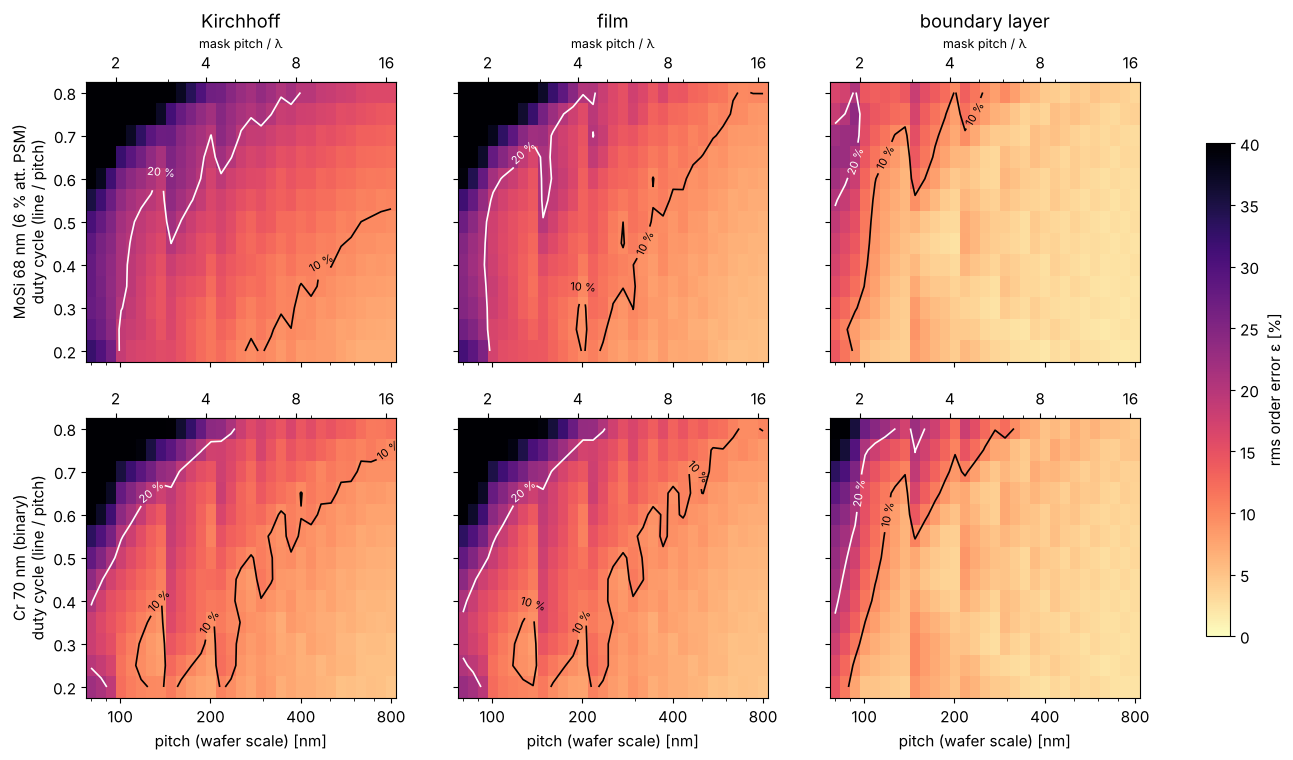

In [7]:
pitches_map = np.geomspace(80, 800, 31)
duties = np.linspace(0.2, 0.8, 13)
eps = {}
t0 = time.time()
for rig in masks:
    for name in ("Kirchhoff", "film", "boundary layer"):
        eps[rig.name, name] = np.zeros((len(duties), len(pitches_map)))
    for j, p in enumerate(pitches_map):
        m = pupil_orders(p)
        for i, d in enumerate(duties):
            layout = MaskLayout.lines_spaces(p, d*p)
            ref = rigorous_orders(rig, layout, m)
            for name in ("Kirchhoff", "film", "boundary layer"):
                a = thin_orders(models(rig)[name], layout, m)
                eps[rig.name, name][i, j] = np.sqrt(np.sum(np.abs(a - ref)**2)/np.sum(np.abs(ref)**2))
print(f"{time.time() - t0:.1f} s")

fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharex=True, sharey=True)
for row, rig in zip(axes, masks):
    for ax, name in zip(row, ("Kirchhoff", "film", "boundary layer")):
        e = 100*eps[rig.name, name]
        im = ax.pcolormesh(pitches_map, duties, e, shading="nearest", cmap="magma_r", vmin=0, vmax=40)
        cs = ax.contour(pitches_map, duties, e, levels=[10, 20], colors=["k", "w"], linewidths=1.2)
        ax.clabel(cs, fmt="%d %%", fontsize=8)
        pitch_axis(ax)
        top = ax.secondary_xaxis("top", functions=(lambda p: M*p/wl, lambda q: q*wl/M))
        top.set_xticks([2, 4, 8, 16]); top.xaxis.set_major_formatter(plt.ScalarFormatter())
        top.xaxis.set_minor_formatter(plt.NullFormatter())
        if rig is masks[0]:
            ax.set_title(name)
            top.set_xlabel("mask pitch / λ", fontsize=9)
    row[0].set_ylabel(f"{rig.name}\nduty cycle (line / pitch)")
for ax in axes[1]:
    ax.set_xlabel("pitch (wafer scale) [nm]")
fig.colorbar(im, ax=axes, label="rms order error ε [%]", shrink=0.8)

for rig in masks:
    i = int(np.argmin(np.abs(duties - 0.5)))
    for name in ("Kirchhoff", "film", "boundary layer"):
        e = eps[rig.name, name][i]
        below = pitches_map[e < 0.1]
        print(f"{rig.name[:4]} {name:15s} 1:1: ε = {100*e[0]:.0f} % at 80 nm, {100*e[-1]:.0f} % at 800 nm; "
              f"ε < 10 % from {below.min() if len(below) else np.nan:.0f} nm pitch")

For 1:1 lines, the rms order error drops below 10 % at the following
pitches:

| model | MoSi | chrome |
|---|---|---|
| Kirchhoff | 635 nm (13 λ on the mask) | 273 nm (5.7 λ) |
| film | 344 nm (7.1 λ) | 273 nm (5.7 λ) |
| boundary layer | 109 nm (2.3 λ) | 117 nm (2.4 λ) |

Below a mask pitch of about 6 λ (pitch 300 nm at 4×), the thin models
are off by more than 10 % for any duty cycle. For MoSi the nominal
Kirchhoff mask fails even at large pitches because of its phase. The
boundary layer moves the limit down to about 2.4 λ.

The duty cycle also matters. Dark lines with narrow spaces (duty cycle
0.7 to 0.8) are the worst case: the space on the mask is then only one or
two wavelengths wide and 70 nm deep, and it acts more like a waveguide
than an aperture. Narrow lines in wide spaces are the easy case. The
boundary layer fails first at narrow spaces too.

## 5. Imaging through pitch

The order errors matter only as far as they change the image. TE-polarized
annular illumination ($\sigma$ 0.6–0.9) as in notebook 36, threshold model
at 0.25, through focus ±80 nm for best focus (vertex of NILS through
focus) and NILS at the printed edges in focus. The grid of pitches and
duty cycles below is used here (1:1) and in section 6 (maps).

Two ways to compare CDs:

- **same dose:** all models at dose 1 and threshold 0.25, as in notebook
  36. This shows the full bias of each model.
- **anchored:** every model gets the dose that prints the 1:1 lines at
  500 nm pitch on size, as a model calibration would do. What is left is
  the error through pitch and duty cycle, which a dose (or a global bias)
  cannot absorb and OPC built on that model would carry to the wafer.

In [8]:
pitches_img = np.array([100, 110, 120, 130, 145, 160, 180, 200, 230, 260, 300, 350, 420, 500])
duties_img = np.array([0.3, 0.4, 0.5, 0.6, 0.7])
anchor = MaskLayout.lines_spaces(500.0, 250.0)
img = {}
t0 = time.time()
for rig in masks:
    for name, stack in models(rig).items():
        dose = LithoSimulation(anchor, stack, ill, projector).dose_to_size(threshold=0.25)
        R = np.full((4, len(duties_img), len(pitches_img)), np.nan)  # CD (same dose), CD (anchored), BF, NILS
        for j, p in enumerate(pitches_img):
            for i, d in enumerate(duties_img):
                sim = LithoSimulation(MaskLayout.lines_spaces(p, d*p), stack, ill, projector)
                r1 = lens.feature_response(sim, threshold=0.25, foci=foci)
                ra = lens.feature_response(sim, threshold=0.25, dose=dose, foci=foci)
                R[:, i, j] = r1.cd, ra.cd, ra.best_focus, ra.nils_focus[i_f0]
        img[rig.name, name] = dose, R
        print(f"{rig.name[:4]} {name:15s} anchor dose {dose:.3f}, {time.time() - t0:.0f} s")

MoSi Kirchhoff       anchor dose 0.823, 0 s


MoSi film            anchor dose 0.820, 1 s


MoSi boundary layer  anchor dose 0.894, 2 s


MoSi RCWA            anchor dose 0.907, 29 s


Cr 7 Kirchhoff       anchor dose 0.706, 29 s


Cr 7 film            anchor dose 0.691, 30 s


Cr 7 boundary layer  anchor dose 0.735, 30 s


Cr 7 RCWA            anchor dose 0.738, 57 s


MoSi Kirchhoff       1:1: ΔCD same dose -36.9… -6.1 nm, anchored -19.8… +0.0 nm, Δ best focus  -3.4… +4.7 nm, NILS  -11… +98 %
MoSi film            1:1: ΔCD same dose -37.2… -6.3 nm, anchored -19.8… +0.0 nm, Δ best focus  +2.2… +6.4 nm, NILS  -11… +97 %
MoSi boundary layer  1:1: ΔCD same dose  -2.5… -0.7 nm, anchored  -1.4… +2.6 nm, Δ best focus  +1.2… +4.0 nm, NILS  -15…  +0 %
Cr 7 Kirchhoff       1:1: ΔCD same dose  -8.4… -2.8 nm, anchored  -7.1… +0.0 nm, Δ best focus  -0.8… +8.9 nm, NILS   -3…  +9 %
Cr 7 film            1:1: ΔCD same dose -11.6… -4.5 nm, anchored  -7.9… +0.0 nm, Δ best focus  -0.7… +7.8 nm, NILS   -5…  +6 %
Cr 7 boundary layer  1:1: ΔCD same dose  -1.7… +0.0 nm, anchored  -1.6… +2.6 nm, Δ best focus  +0.2… +3.4 nm, NILS  -10…  +2 %


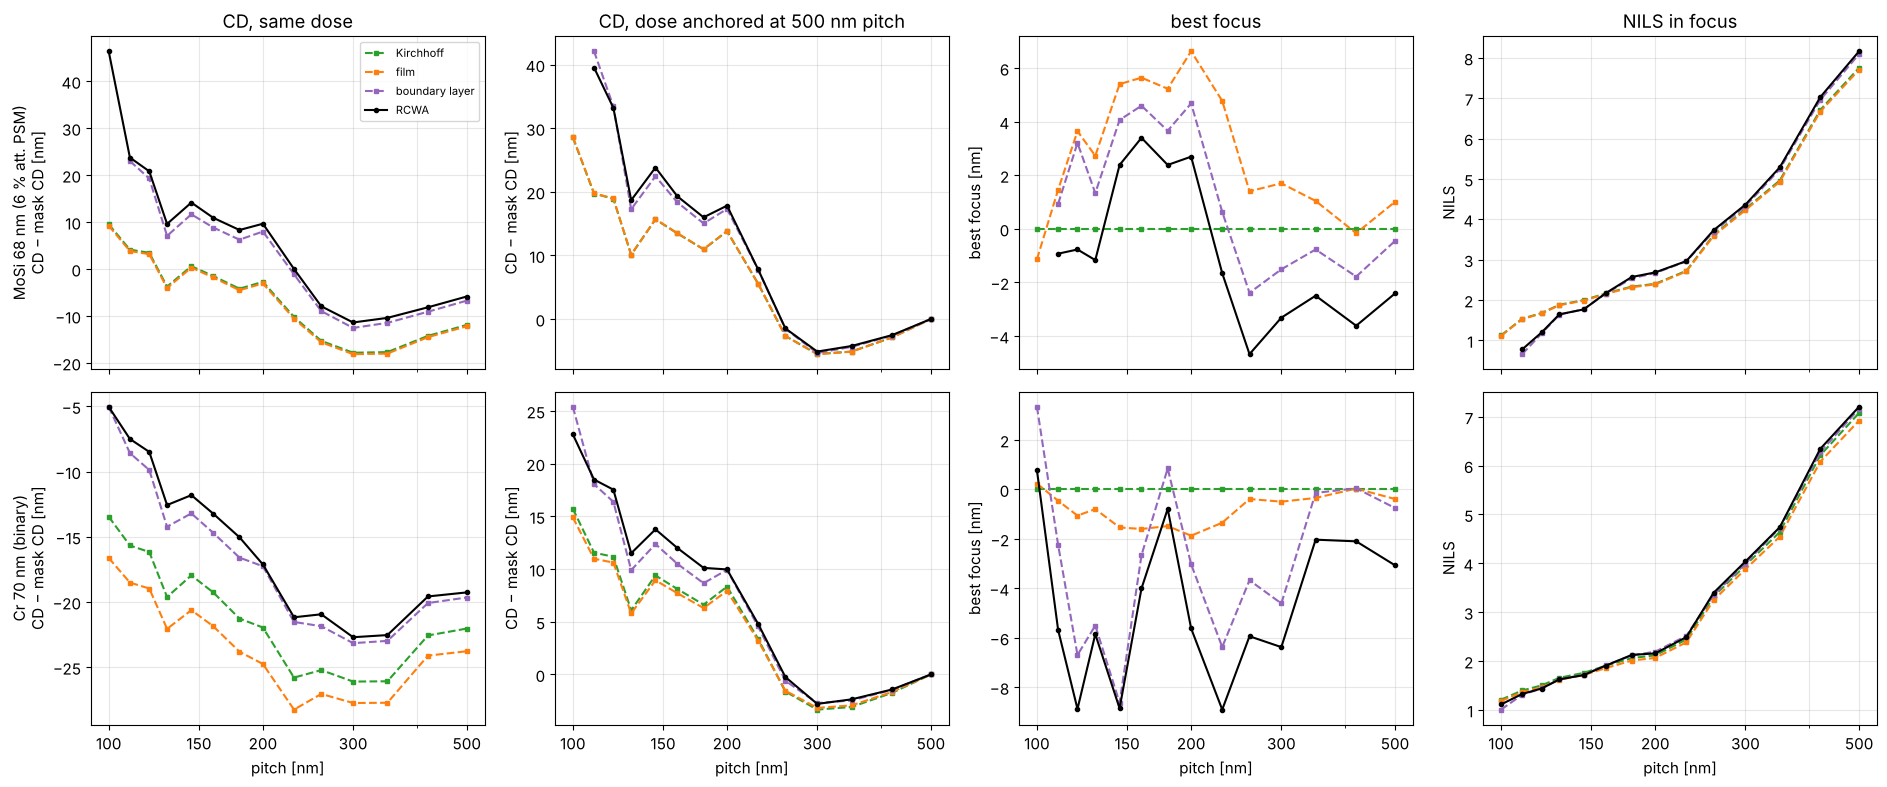

In [9]:
i5 = int(np.argmin(np.abs(duties_img - 0.5)))
fig, axes = plt.subplots(2, 4, figsize=(19, 8), sharex=True)
for row, rig in zip(axes, masks):
    for name in models(rig):
        _, R = img[rig.name, name]
        ls, mk = ("-", "o") if name == "RCWA" else ("--", "s")
        kw = dict(color=colors[name], ls=ls, marker=mk, ms=3, label=name)
        row[0].plot(pitches_img, R[0, i5] - pitches_img/2, **kw)
        row[1].plot(pitches_img, R[1, i5] - pitches_img/2, **kw)
        row[2].plot(pitches_img, R[2, i5], **kw)
        row[3].plot(pitches_img, R[3, i5], **kw)
    row[0].set_ylabel(f"{rig.name}\nCD − mask CD [nm]")
    row[1].set_ylabel("CD − mask CD [nm]"); row[2].set_ylabel("best focus [nm]"); row[3].set_ylabel("NILS")
axes[0, 0].set_title("CD, same dose"); axes[0, 1].set_title("CD, dose anchored at 500 nm pitch")
axes[0, 2].set_title("best focus"); axes[0, 3].set_title("NILS in focus")
for ax in axes.flat:
    pitch_axis(ax, (100, 150, 200, 300, 500)); ax.grid(alpha=0.3, which="both")
for ax in axes[1]:
    ax.set_xlabel("pitch [nm]")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()

for rig in masks:
    _, ref = img[rig.name, "RCWA"]
    for name in ("Kirchhoff", "film", "boundary layer"):
        dose, R = img[rig.name, name]
        d_cd1, d_cda = R[0, i5] - ref[0, i5], R[1, i5] - ref[1, i5]
        bf = R[2, i5] - ref[2, i5]
        nils = 100*(R[3, i5]/ref[3, i5] - 1)
        print(f"{rig.name[:4]} {name:15s} 1:1: ΔCD same dose {np.nanmin(d_cd1):+5.1f}…{np.nanmax(d_cd1):+5.1f} nm, "
              f"anchored {np.nanmin(d_cda):+5.1f}…{np.nanmax(d_cda):+5.1f} nm, "
              f"Δ best focus {np.nanmin(bf):+5.1f}…{np.nanmax(bf):+5.1f} nm, "
              f"NILS {np.nanmin(nils):+4.0f}…{np.nanmax(nils):+4.0f} %")

- **Same dose:** the rigorous MoSi lines print 6 to 37 nm wider than the
  Kirchhoff and film models predict, and chrome lines 3 to 12 nm wider. The
  boundary layer is within 2.5 nm.
- **Anchored:** a large part of that is just a dose offset. The rigorous
  MoSi mask needs about 10 % more dose than the thin ones to print the
  500 nm pitch on size (0.907 against 0.823), chrome 5 % (0.738 against
  0.706). What is left varies through pitch, and that is what OPC has to
  correct: up to 20 nm for MoSi near the resolution limit (110 to 130 nm
  pitch) and 7 to 8 nm for chrome. With the boundary layer, the residual
  stays between −1.6 and +2.6 nm.
- **Best focus:** Kirchhoff gives the same best focus for all pitches,
  because its orders have no phase errors. The film model has some phase
  (MoSi at 165°) and shifts best focus by a few nanometres. RCWA shifts
  best focus by 8 nm through pitch for MoSi and by about 10 nm for chrome.
  That costs common depth of focus, and the thin models miss it. The
  boundary layer follows most of it, within 2 to 4 nm.
- **NILS:** all models agree within a few percent over most of the pitch
  range. The exception is the resolution limit, where the rigorous lines
  barely resolve (NILS below 1) and the thin models are much too
  optimistic (MoSi Kirchhoff +98 % at 110 nm). Near 500 nm pitch the
  rigorous image is 3 % to 6 % steeper, partly because of its higher
  anchored dose.

## 6. Imaging errors over pitch and duty cycle

For each thin model against RCWA: the anchored CD error (top row), the
best focus error relative to the anchor (middle row; a constant best focus
offset is a focus calibration, only the variation through pitch costs
common depth of focus) and the relative NILS error (bottom row). Crosses
mark |ΔCD| > 1 nm, a typical budget for a mask model. White cells: the
feature does not print with RCWA at that dose (the lines merge or vanish).

MoSi Kirchhoff       |ΔCD| ≤ 1 nm in  33 % of the layouts, max. 19.8 nm, rms 5.1 nm
MoSi film            |ΔCD| ≤ 1 nm in  33 % of the layouts, max. 19.8 nm, rms 5.1 nm
MoSi boundary layer  |ΔCD| ≤ 1 nm in  87 % of the layouts, max. 2.6 nm, rms 0.8 nm
Cr 7 Kirchhoff       |ΔCD| ≤ 1 nm in  43 % of the layouts, max. 11.2 nm, rms 3.3 nm
Cr 7 film            |ΔCD| ≤ 1 nm in  39 % of the layouts, max. 12.7 nm, rms 3.8 nm
Cr 7 boundary layer  |ΔCD| ≤ 1 nm in  64 % of the layouts, max. 4.6 nm, rms 1.2 nm


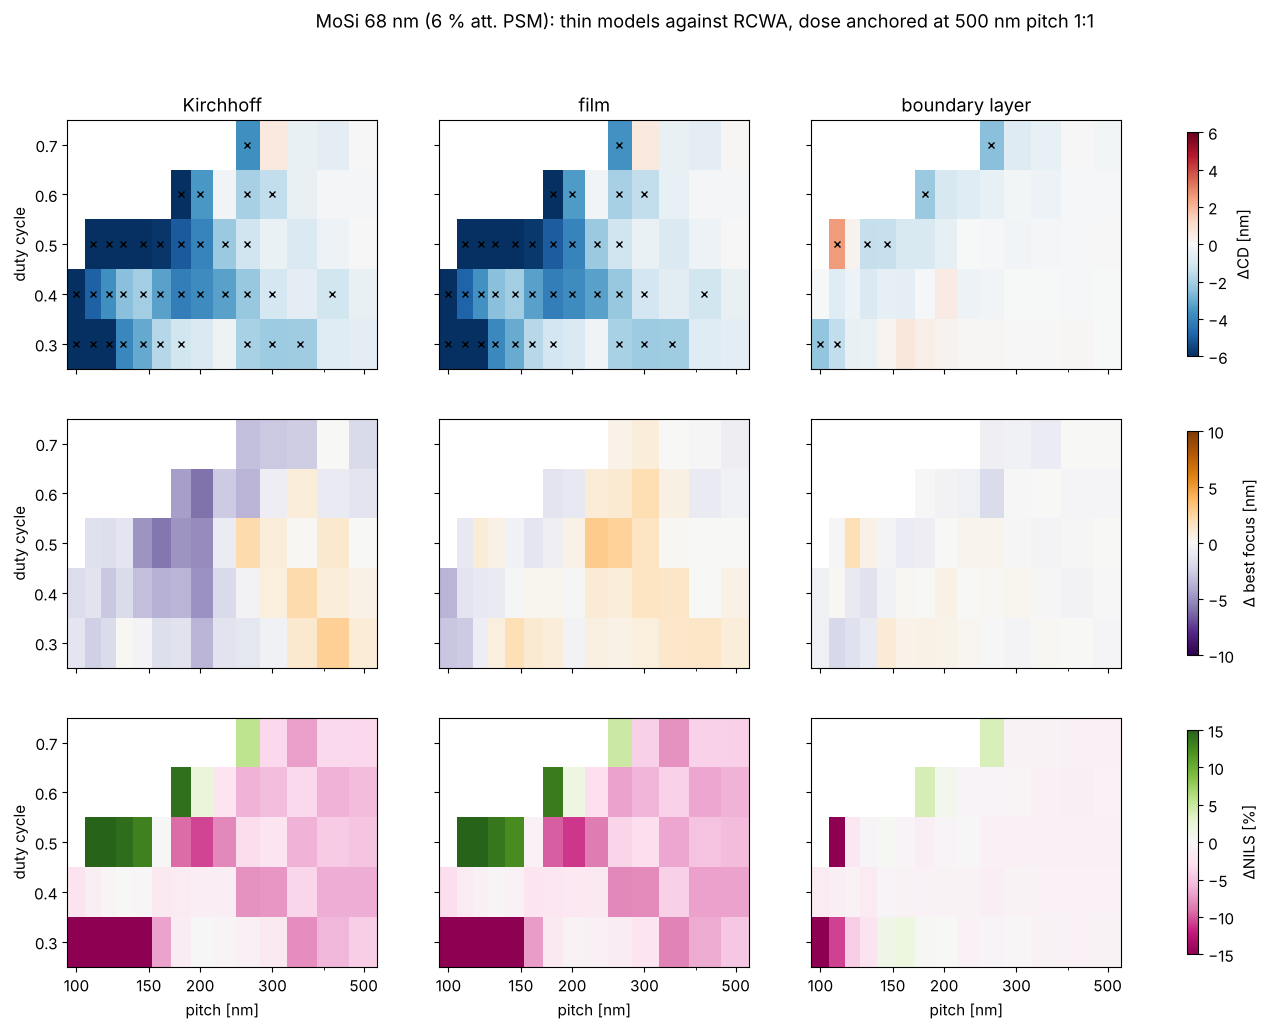

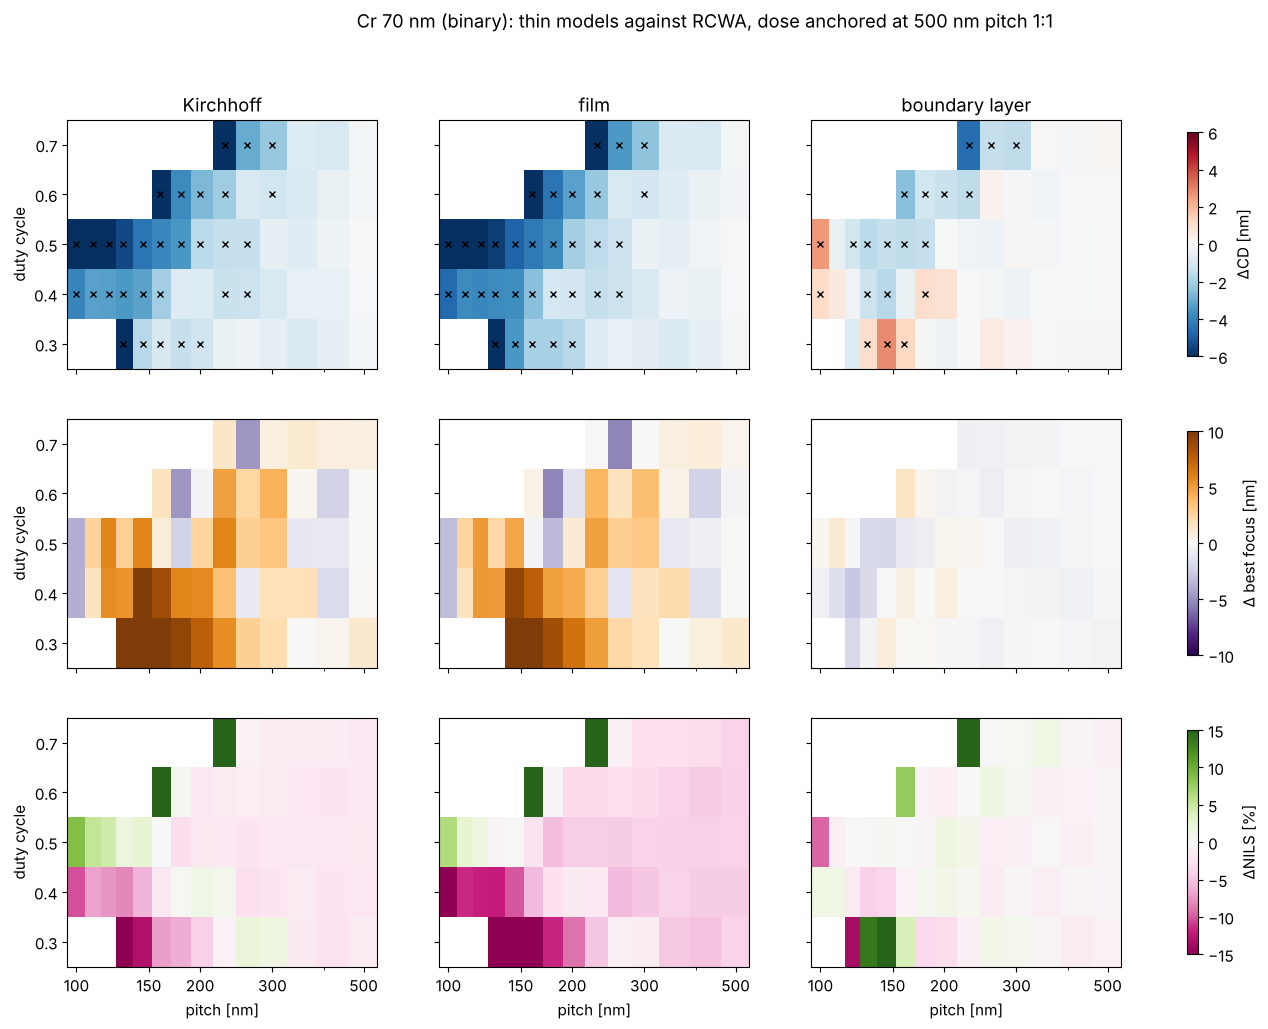

In [10]:
names = ("Kirchhoff", "film", "boundary layer")
j_anchor, i_anchor = len(pitches_img) - 1, i5
for rig in masks:
    _, ref = img[rig.name, "RCWA"]
    fig, axes = plt.subplots(3, 3, figsize=(17, 11), sharex=True, sharey=True)
    for col, name in enumerate(names):
        _, R = img[rig.name, name]
        d_cd = R[1] - ref[1]
        d_bf = (R[2] - R[2, i_anchor, j_anchor]) - (ref[2] - ref[2, i_anchor, j_anchor])
        d_nils = 100*(R[3]/ref[3] - 1)
        for row, (v, lim, cmap, lab) in enumerate(((d_cd, 6, "RdBu_r", "ΔCD [nm]"),
                                                   (d_bf, 10, "PuOr_r", "Δ best focus [nm]"),
                                                   (d_nils, 15, "PiYG", "ΔNILS [%]"))):
            ax = axes[row, col]
            im = ax.pcolormesh(pitches_img, duties_img, v, shading="nearest", cmap=cmap, vmin=-lim, vmax=lim)
            if row == 0:
                jj, ii = np.meshgrid(pitches_img, duties_img)
                bad = np.abs(v) > 1.0
                ax.plot(jj[bad], ii[bad], "kx", ms=5)
                ax.set_title(name)
            pitch_axis(ax, (100, 150, 200, 300, 500))
            if col == 2:
                fig.colorbar(im, ax=axes[row], label=lab, shrink=0.9)
        axes[2, col].set_xlabel("pitch [nm]")
    for ax in axes[:, 0]:
        ax.set_ylabel("duty cycle")
    fig.suptitle(f"{rig.name}: thin models against RCWA, dose anchored at 500 nm pitch 1:1")

for rig in masks:
    _, ref = img[rig.name, "RCWA"]
    for name in names:
        _, R = img[rig.name, name]
        d_cd = np.abs(R[1] - ref[1])
        ok = np.isfinite(d_cd)
        print(f"{rig.name[:4]} {name:15s} |ΔCD| ≤ 1 nm in {100*np.mean(d_cd[ok] <= 1):3.0f} % of the layouts, "
              f"max. {np.nanmax(d_cd):.1f} nm, rms {np.sqrt(np.nanmean(d_cd**2)):.1f} nm")

Share of layouts within the 1 nm budget and the rms error after dose
anchoring:

| | MoSi | chrome |
|---|---|---|
| Kirchhoff | 33 %, rms 5.1 nm, max. 20 nm | 43 %, rms 3.3 nm, max. 11 nm |
| film | 33 %, rms 5.1 nm, max. 20 nm | 39 %, rms 3.8 nm, max. 13 nm |
| boundary layer | 87 %, rms 0.8 nm, max. 2.6 nm | 64 %, rms 1.2 nm, max. 4.6 nm |

- The thin models fail below about 250 nm pitch for every duty cycle. At
  large duty cycles (narrow spaces) they are 1 to 3 nm off even at 300 to
  500 nm pitch.
- Best focus: chrome is the critical case. Narrow lines (duty cycle 0.3
  to 0.4) at 130 to 200 nm pitch have their best focus 5 to 12 nm away
  from the thin model prediction. The boundary layer stays within about
  2 nm.
- NILS: errors above 10 % appear only along the printing limit (the
  white region).
- The boundary layer fails at the smallest pitches (below 120 nm) and at
  narrow spaces (duty cycle 0.6 to 0.7, 160 to 260 nm pitch), where it is
  off by 3 to 4 nm. That is the regime of strong coupling between
  neighbouring edges, and of the angle dependence of section 3 in
  notebook 36, which a calibration at normal incidence cannot capture.

## Summary

| model | order error < 10 % (1:1) | CD after dose calibration (rms / max.) | best focus through pitch | cost |
|---|---|---|---|---|
| Kirchhoff | pitch ≥ 270 nm (Cr), ≥ 640 nm (MoSi) | 3–5 nm / 11–20 nm | none (wrong) | ≈ ms |
| film | ≥ 270 nm (Cr), ≥ 340 nm (MoSi) | 4–5 nm / 13–20 nm | partly | ≈ ms |
| boundary layer | ≥ 110–120 nm | 0.8–1.2 nm / 2.6–4.6 nm | within 2–4 nm | ≈ ms |
| RCWA | reference | 0.03–0.3 nm convergence error at the default `n_orders` | reference | ≈ 0.1–2 s per layout |

- **Is the thin mask good enough?** It is for mask pitches above about
  6 λ (1:1, order error below 10 %), and not at all for the 1 nm CD budget
  of modern nodes below about 250 nm wafer pitch. For an att. PSM, the
  nominal Kirchhoff mask (6 %, 180°) should not be used at all, because
  the real film phase (165° here) is a first-order effect. The film model
  fixes this.
- **The boundary layer** is the best value: same speed as the thin
  models, about 5 times smaller CD errors, and best focus through pitch.
  It fails at narrow spaces and at the smallest pitches.
- **RCWA** is needed for best focus and CD near the resolution limit, for
  narrow spaces, and for calibrating the boundary layer. The default
  harmonics are good to 0.3 nm of CD; double them for sub-0.1 nm work on
  MoSi.
- Here RCWA takes about 30 times as long as the thin models for the
  whole imaging grid (about 30 s per mask, against 1 s).
- Limitations: 1D lines and spaces, TE annular illumination, and threshold
  resist. Notebook 36 covers the angle dependence of the orders and Abbe
  against Hopkins.